In [4]:
from dotenv import load_dotenv

load_dotenv()

True

In [2]:
from tavily import TavilyClient
from typing import Literal

tavily_client = TavilyClient()

def web_search(query:str, max_results:int=5, topic: Literal["general","sports","news","finance"]='general',
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)

In [17]:
from langchain_groq import ChatGroq

model=ChatGroq(model="qwen/qwen3.6-27b")
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.5', 'langchain': '1.3.15'}}, client=<groq.resources.chat.completions.Completions object at 0x11c3c9a50>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x11c3cbbd0>, model_name='qwen/qwen3.6-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

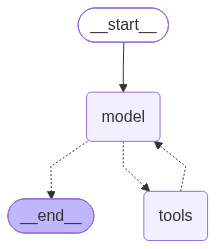

In [11]:
## Basic Agent
from langchain.agents import create_agent


simple_agent=create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

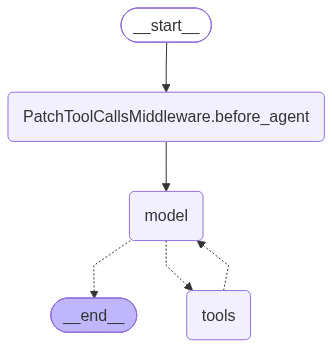

In [18]:
### Create a deep agent
## Prompt

## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [19]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='aa98bfea-83f2-4336-8b9a-5fbc7fbba3a1'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user is asking "What is deepagent?".\nThis sounds like a request for information about a specific software library, framework, or concept.\nI should search for "deepagent" to see if it refers to a known project (e.g., a Python library, an AI agent framework).\nI will use the `web_search` tool.\n', 'tool_calls': [{'id': 'n58p0f1r3', 'function': {'arguments': '{"query":"What is deepagent?"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 104, 'prompt_tokens': 2616, 'total_tokens': 2720, 'completion_time': 0.197587824, 'completion_tokens_details': {'reasoning_tokens': 72}, 'prompt_time': 0.192270391, 'prompt_tokens_details': None, 'queue_time': 0.051566638, 'total_time': 0.389858215}, 'model_name': 'qwen/qwen3.6-27b', 'syst